
**Transportation and Logistics Tracking**




About DataSet

The Transportation and Logistics Tracking Dataset comprises multiple datasets related to various aspects of transportation and logistics operations. It includes information on on-time delivery impact, routes by rating, customer ratings, delivery times with and without congestion, weather conditions, and differences between fixed and main delivery times across different regions

In [ ]:
# import pandas
import pandas as pd

In [ ]:
#connecting to google colab with drive
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# loading the dataset

file_path = "/content/drive/MyDrive/FINAL PROJECT/TRANSPORTATION AND LOGISTICS DATASET/Transportation And Logistic data.xlsx"
TL = pd.read_excel(file_path)
# First 5 rows of The Data Set
TL.head()

,GpsProvider,BookingID,Market/Regular,BookingID_Date,vehicle_no,Origin_Location,Destination_Location,Org_lat_lon,Des_lat_lon,Data_Ping_time,...,TRANSPORTATION_DISTANCE_IN_KM,vehicleType,Minimum_kms_to_be_covered_in_a_day,Driver_Name,Driver_MobileNo,customerID,customerNameCode,supplierID,supplierNameCode,Material Shipped
0,CONSENT TRACK,MVCV0000927/082021,Market,2020-08-17 14:59:01.000,KA590408,"TVSLSL-PUZHAL-HUB,CHENNAI,TAMIL NADU","ASHOK LEYLAND PLANT 1- HOSUR,HOSUR,KARNATAKA","13.1550,80.1960","12.7400,77.8200",2020-08-24 00:05:09,...,320.0,32 FT Single-Axle 7MT - HCV,NaN,NaN,NaN,ALLEXCHE45,Ashok leyland limited,VIJEXHOSR7,VIJAY TRANSPORT,BRACKET / GRAB HANDLE
1,VAMOSYS,VCV00014271/082021,Regular,2020-08-27 16:22:22.827,TN30BC5917,"DAIMLER INDIA COMMERCIAL VEHICLES,KANCHIPURAM,...","DAIMLER INDIA COMMERCIAL VEHICLES,KANCHIPURAM,...","12.8390,79.9540","12.8390,79.9540",2020-08-28 12:40:28,...,103.0,32 FT Multi-Axle 14MT - HCV,NaN,RAMESH,NaN,DMREXCHEUX,Daimler india commercial vehicles pvt lt,VJLEXSHE09,VJ LOGISTICS,ZB MODEL PLATE / 3143
2,CONSENT TRACK,VCV00014382/082021,Regular,2020-08-27 17:59:24.987,TN22AR2748,"LUCAS TVS LTD-PONDY,PONDY,PONDICHERRY","LUCAS TVS LTD-PONDY,PONDY,PONDICHERRY","11.8710,79.7390","11.8710,79.7390",2020-08-28 09:05:09,...,300.0,1 MT Tata Ace (Open Body),NaN,GIRI,NaN,LUTGCCHE06,Lucas tvs ltd,GSTEXLAK1Q,G.S. TRANSPORT,LETTERING / FUSO
3,VAMOSYS,VCV00014743/082021,Regular,2020-08-28 00:48:24.503,TN28AQ0781,"DAIMLER INDIA COMMERCIAL VEHICLES,KANCHIPURAM,...","DAIMLER INDIA COMMERCIAL VEHICLES,KANCHIPURAM,...","12.8390,79.9540","12.8390,79.9540",2020-08-28 12:40:31,...,61.0,32 FT Multi-Axle 14MT - HCV,NaN,RAVI,NaN,DMREXCHEUX,Daimler india commercial vehicles pvt lt,ARVEXNAM09,ARVINTH TRANSPORT,LU STRUT RA / RADIUS ROD
4,VAMOSYS,VCV00014744/082021,Regular,2020-08-28 01:23:19.243,TN68F1722,"LUCAS TVS LTD-PONDY,PONDY,PONDICHERRY","LUCAS TVS LTD-PONDY,PONDY,PONDICHERRY","11.8720,79.6320","11.8720,79.6320",2020-08-28 12:40:29,...,240.0,32 FT Multi-Axle 14MT - HCV,NaN,TAMIL,NaN,LUTGCCHE06,Lucas tvs ltd,SRTEXKOR96,SR TRANSPORTS,WISHBONE / V ROD/HDT


In [ ]:
#information Of Dataset
TL.info(
)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6880 entries, 0 to 6879
Data columns (total 32 columns):
 #   Column                              Non-Null Count  Dtype         
---  ------                              --------------  -----         
 0   GpsProvider                         5927 non-null   object        
 1   BookingID                           6880 non-null   object        
 2   Market/Regular                      6880 non-null   object        
 3   BookingID_Date                      6880 non-null   datetime64[ns]
 4   vehicle_no                          6880 non-null   object        
 5   Origin_Location                     6880 non-null   object        
 6   Destination_Location                6880 non-null   object        
 7   Org_lat_lon                         6880 non-null   object        
 8   Des_lat_lon                         6880 non-null   object        
 9   Data_Ping_time                      5927 non-null   datetime64[ns]
 10  Planned_ETA             

In [ ]:
# Total Rows And Column
TL.shape


(6880, 22)

DATA CLEANING


---


DELETING UNWANTED COLUMN

For Python Data Analytics project, We can remove unwanted columns from the transportation dataset using Pandas. Since dataset focuses on vehicle trips, delivery delays, locations, and transportation distance .

In [ ]:
# To check whether the dataset contains duplicate values.
# Check duplicate column names
print("Duplicate columns:")
print(TL.columns[TL.columns.duplicated()].tolist())

Duplicate columns:
[]


In [ ]:
# Columns to delete
# * GpsProvider * Org_lat_lon  *Des_lat_lon  *DestinationLocationn *OriginLocation_Code * DestinationLocation_Code  *
# * Driver_Name * Driver_MobileNo * customerNameCode * supplierNameCode
unwanted_columns = [
    'GpsProvider',
    'Org_lat_lon',
    'Des_lat_lon',
    'DestinationLocation',
    'OriginLocation_Code',
    'DestinationLocation_Code',
    'Driver_Name',
    'Driver_MobileNo',
    'customerNameCode',
    'supplierNameCode'
]

# Delete the unwanted columns
TL.drop(columns=unwanted_columns, inplace=True, errors='ignore')

# DELETED 10 ROWS


**Data Cleaning**

In [ ]:
# CHECKING WHETHER ANY COLUMN CONTAINS MISSING OR NULL VALUES
missing = TL.isnull().sum()
print(missing[missing > 0])

Data_Ping_time                         953
Current_Location                       964
actual_eta                              37
Curr_lat                               953
Curr_lon                               953
ontime                                4332
delay                                 2538
trip_end_date                          194
TRANSPORTATION_DISTANCE_IN_KM          712
vehicleType                            769
Minimum_kms_to_be_covered_in_a_day    4060
dtype: int64


COLUMN CONTAIN MISSING VALUES AND NULL VALUES ARE


---



Data_Ping_time                       ,
Current_Location                      ,
actual_eta                              ,
Curr_lat                               ,
Curr_lon                               ,
ontime                                ,
delay                                 ,
trip_end_date                          ,
TRANSPORTATION_DISTANCE_IN_KM          ,
vehicleType                            ,
Minimum_kms_to_be_covered_in_a_day


*   VEHICLE THAT ARRIVED ON SCHEDULE APPEAR AS NULL VALUES IN THE DELAY COLUMN, WHILE VEHICLE THAT WERE DELAYS APPEAR AS NULL VALUES IN ONTIME COLUMN, SHOWING A CLEAR CORRELATION BETWEEEN TWO COLUMN.




In [ ]:
# CONVERTING  'Data_Ping_time ,Planned_ETA actual_eta, trip_start_date, trip_end_date' TO DATE AND TIME FORMATE
datetime_columns = [
    'Data_Ping_time',
    'Planned_ETA',
    'actual_eta',
    'trip_start_date',
    'trip_end_date'
]

for col in datetime_columns:
    if col in TL.columns:
        TL[col] = pd.to_datetime(TL[col], errors='coerce')

print(TL[datetime_columns].dtypes)

TL['Data_Ping_time'].dt.strftime('%d-%m-%Y %H:%M:%S').head()

Data_Ping_time     datetime64[ns]
Planned_ETA        datetime64[ns]
actual_eta         datetime64[ns]
trip_start_date    datetime64[ns]
trip_end_date      datetime64[ns]
dtype: object


,Data_Ping_time
0,24-08-2020 00:05:09
1,28-08-2020 12:40:28
2,28-08-2020 09:05:09
3,28-08-2020 12:40:31
4,28-08-2020 12:40:29


CONVERTING NULL AND MISSING VALUES TO USEFULL FORMATE

In [ ]:
# CONVERGTING PING DATA TIME & CURRENT LOCATION NULL VALUES TO NOT AVAILABLE.()
TL['Data_Ping_time'] = TL['Data_Ping_time'].fillna('Not Available')
TL['Current_Location'] = TL['Current_Location'].fillna('Not Available')

# CONVERTING NULL VALUES IN ACTUAL_ETA TO ONTIME OR DELAY ACCORDING TO DELAY AND ONTIME COLUMN


TL['actual_eta'] = TL['actual_eta'].fillna(0)


print("\n\n")

# CURRENT LANGITUDE AND LOGITUDE HAVE 953 NULL VALUES
# Replace NULL values with 'No Information'
TL[['Curr_lat', 'Curr_lon']] = TL[['Curr_lat', 'Curr_lon']].fillna(0)

# Print the result
print("Result after replacing NULL values:\n")

print(TL[['Curr_lat', 'Curr_lon']].head(10))

# Check remaining NULL values
print("\nRemaining NULL values:\n")
print(TL[['Curr_lat', 'Curr_lon']].isnull().sum())






Result after replacing NULL values:

    Curr_lat   Curr_lon
0  12.663500  78.649870
1  12.836757  79.954428
2  13.073956  80.225780
3  12.836686  79.950560
4  12.429501  79.831556
5  13.017365  79.962313
6  11.625962  78.157271
7  12.836837  79.951003
8  12.810470  78.740460
9  12.837941  79.951967

Remaining NULL values:

Curr_lat    0
Curr_lon    0
dtype: int64


In [ ]:
# convertion the null column by using the average of trip starting and end.

# Convert columns to datetime
TL['trip_start_date'] = pd.to_datetime(
    TL['trip_start_date'], errors='coerce'
)
TL['trip_end_date'] = pd.to_datetime(
    TL['trip_end_date'], errors='coerce'
)

# Calculate trip duration for rows with both dates
valid = TL['trip_start_date'].notna() & TL['trip_end_date'].notna()
duration = (
    TL.loc[valid, 'trip_end_date'] - TL.loc[valid, 'trip_start_date']
)

# Use the average duration to fill missing end dates
avg_duration = duration[duration >= pd.Timedelta(0)].mean()

mask = TL['trip_end_date'].isna() & TL['trip_start_date'].notna()

TL.loc[mask, 'trip_end_date'] = (
    TL.loc[mask, 'trip_start_date'] + avg_duration
)

# Print results
print("Average trip duration:", avg_duration)
print("\nUpdated trip end dates:")
print(TL[['trip_start_date', 'trip_end_date']].head(10))

print("\nRemaining NULL values:", TL['trip_end_date'].isna().sum())




Average trip duration: 5 days 08:08:32.891147627

Updated trip end dates:
      trip_start_date                 trip_end_date
0 2020-08-17 14:59:01 2020-08-22 23:07:33.891147627
1 2020-08-27 16:21:52 2020-09-02 00:30:24.891147627
2 2020-08-27 17:57:04 2020-09-02 02:05:36.891147627
3 2020-08-28 00:47:45 2020-09-02 08:56:17.891147627
4 2020-08-28 01:13:48 2020-09-02 09:22:20.891147627
5 2020-08-28 02:13:39 2020-09-02 10:22:11.891147627
6 2020-08-28 02:19:47 2020-09-02 10:28:19.891147627
7 2020-08-28 09:21:56 2020-09-02 17:30:28.891147627
8 2020-08-28 09:38:30 2020-09-02 17:47:02.891147627
9 2020-08-27 22:27:14 2020-09-02 06:35:46.891147627

Remaining NULL values: 0


There are 4,060 null values out of 6,880 rows in Minimum_kms_to_be_covered_in_a_day, so this column will also be deleted.



In [ ]:
TL.drop(columns=['Minimum_kms_to_be_covered_in_a_day'], inplace=True)

**Exploratory Data Analysis (EDA) & Data Visualisation**






Find the most common vehicle types



In [ ]:
TL["vehicleType"].value_counts()

,count
vehicleType,
40 FT 3XL Trailer 35MT,2575
32 FT Multi-Axle 14MT - HCV,982
40 FT Flat Bed Multi-Axle 27MT - Trailer,670
32 FT Single-Axle 7MT - HCV,510
28 FT Open Body 25MT,171
24 / 26 FT Taurus Open 21MT - HCV,158
24 | 26 FT Taurus Open 21MT - HCV,157
40 FT Flat Bed Double-Axle 21MT - Trailer,152
22 FT Taurus Open 16MT - HCV,133


Importing  Libraries


1.   Seaborn
2.   Matplotlib





In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

Analyze Transportation Distance

count    6168.000000
mean      553.856282
std       758.981836
min         0.000000
25%        40.000000
50%       160.000000
75%       900.000000
max      2954.700000
Name: TRANSPORTATION_DISTANCE_IN_KM, dtype: float64


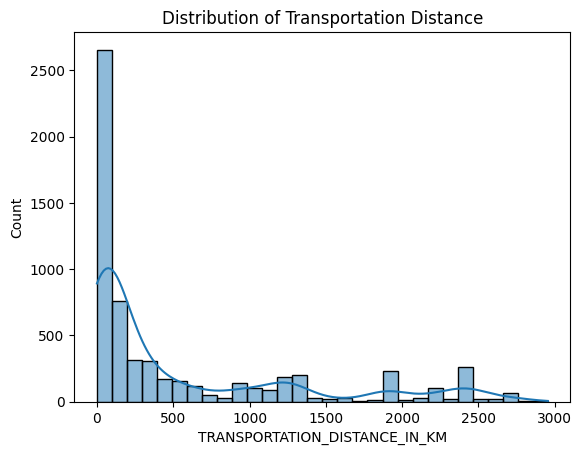

In [ ]:
print(TL['TRANSPORTATION_DISTANCE_IN_KM'].describe())

sns.histplot(
    data=TL,
    x='TRANSPORTATION_DISTANCE_IN_KM',
    bins=30,
    kde=True
)

plt.title('Distribution of Transportation Distance')
plt.show()

Find The Most Frequent Origins And Destinations

In [ ]:
print(TL['Origin_Location'].value_counts().head(10))
print("-----------------------------------------")
print(TL['Destination_Location'].value_counts().head(10))

Origin_Location
Mugabala, Bangalore Rural, Karnataka                        572
Shive, Pune, Maharashtra                                    428
Sedarapet, India                                            409
DAIMLER INDIA COMMERCIAL VEHICLES,KANCHIPURAM,TAMIL NADU    341
Kollur, Medak, Telangana                                    333
Jamalpur, Gurgaon, Haryana                                  254
Manali, Tiruvallur, Tamil Nadu                              234
Ramamurthy Nagar, Bangalore, Karnataka                      219
Khorajnanoda, Ahmedabad, Gujarat                            217
Kalamboli Node, Raigarh, Maharashtra                        182
Name: count, dtype: int64
-----------------------------------------
Destination_Location
DAIMLER INDIA COMMERCIAL VEHICLES,KANCHIPURAM,TAMIL NADU    342
Singaperumalkoil, Kanchipuram, Tamil Nadu                   252
Bangalore International Airport, Bangalore, Karnataka       243
Pondur, Kanchipuram, Tamil Nadu                             209

Vehicle Type Versus Delivery Status

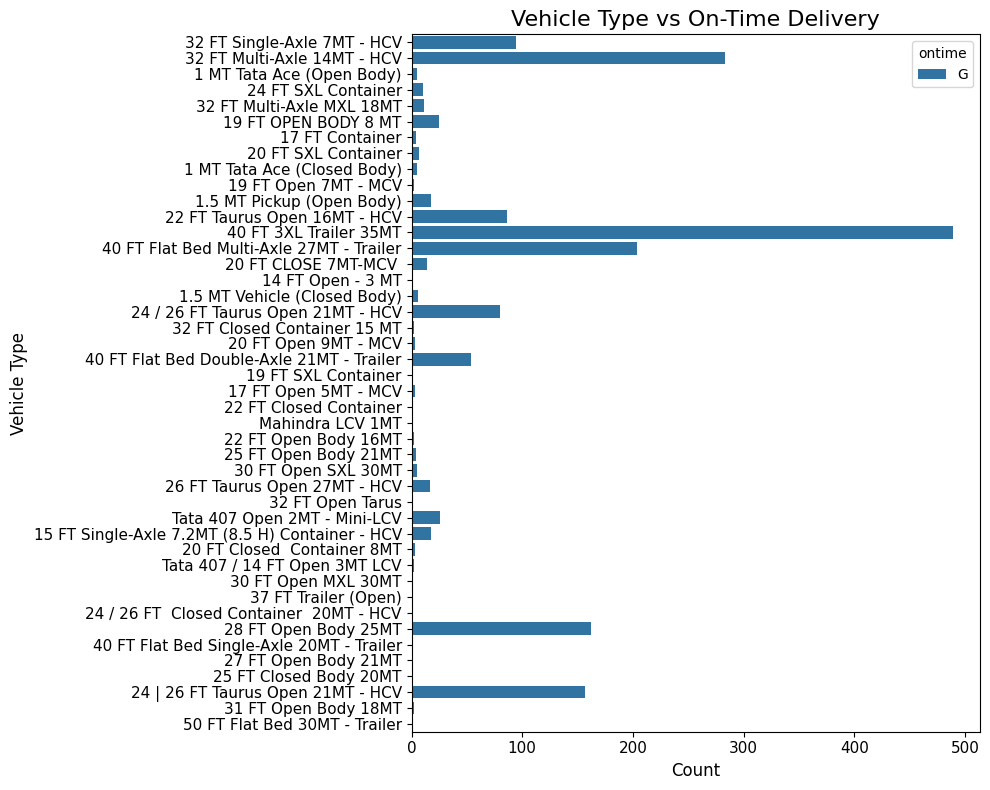

In [ ]:
plt.figure(figsize=(10, 8))

sns.countplot(
    data=TL,
    y="vehicleType",
    hue="ontime"
)

plt.title("Vehicle Type vs On-Time Delivery", fontsize=16)
plt.xlabel("Count", fontsize=12)
plt.ylabel("Vehicle Type", fontsize=12)
plt.xticks(fontsize=11)
plt.yticks(fontsize=11)

plt.tight_layout()
plt.show()

On-time vs delayed bookings

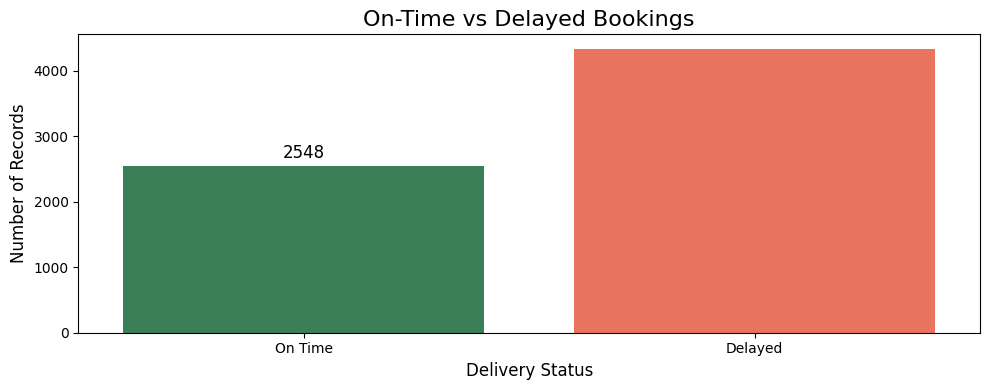

On Time    2548
Delayed    4342
dtype: int64


In [ ]:

# Count records by delivery status
status = pd.Series({
    "On Time": TL["ontime"].notna().sum(),
    "Delayed": TL["delay"].notna().sum()
})

plt.figure(figsize=(10, 4))

ax = sns.barplot(
    x=status.index,
    y=status.values,
    hue=status.index,
    palette=["seagreen", "tomato"],
    legend=False
)

# Display counts above bars
ax.bar_label(ax.containers[0], fontsize=12, padding=3)

plt.title("On-Time vs Delayed Bookings", fontsize=16)
plt.xlabel("Delivery Status", fontsize=12)
plt.ylabel("Number of Records", fontsize=12)
plt.tight_layout()
plt.show()

print(status)

 Market type versus delivery status

In [ ]:
print([
    col for col in TL.columns
    if "market" in col.lower() or "regular" in col.lower()
])

print(TL['Market/Regular '].value_counts(dropna=False))

['Market/Regular ']
Market/Regular 
Regular    6811
Market       69
Name: count, dtype: int64


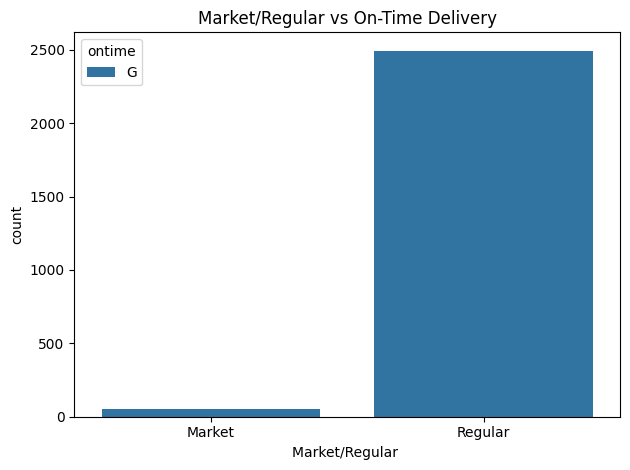

In [ ]:
sns.countplot(
    data=TL,
    x='Market/Regular ',
    hue="ontime"
)

plt.title("Market/Regular vs On-Time Delivery")
plt.tight_layout()
plt.show()

**Time-based analysis**

 Bookings by month



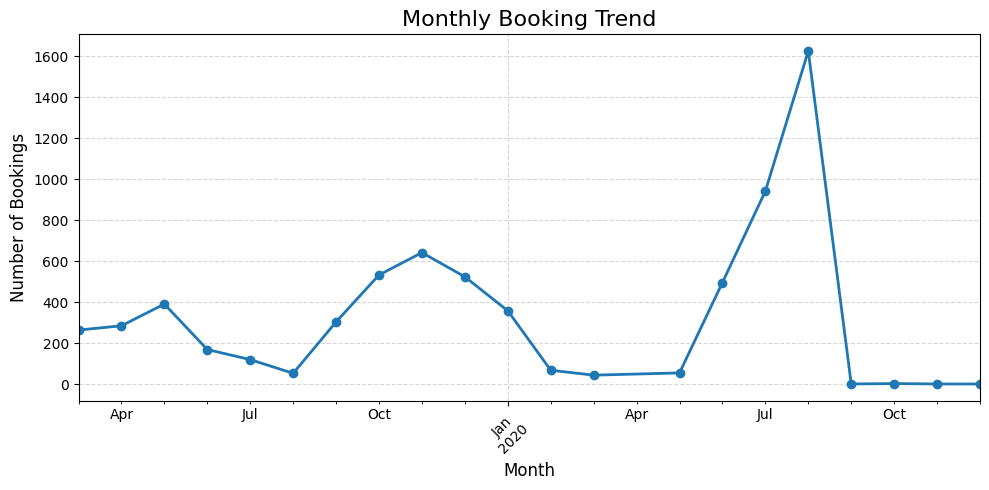

In [ ]:

# Extract booking month
TL["booking_month"] = TL["BookingID_Date"].dt.to_period("M")

# Count monthly bookings
monthly_bookings = TL.groupby("booking_month").size()

# Plot the trend
plt.figure(figsize=(10,5 ))

monthly_bookings.plot(kind="line", marker="o", linewidth=2)

plt.title("Monthly Booking Trend", fontsize=16)
plt.xlabel("Month", fontsize=12)
plt.ylabel("Number of Bookings", fontsize=12)
plt.xticks(rotation=45)
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

 Most frequently used routes

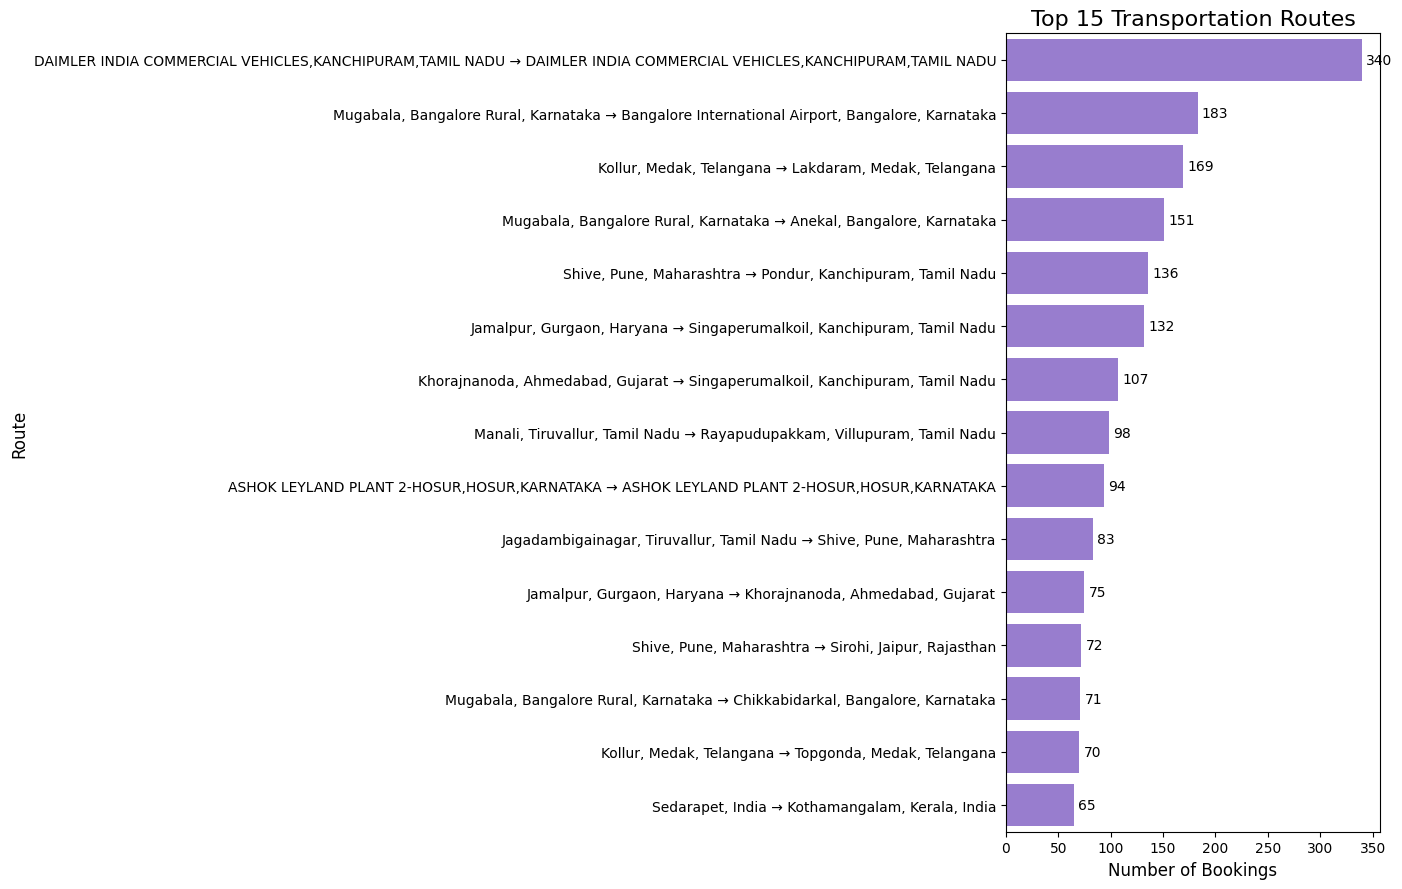

In [ ]:
# Create Route column
TL["Route"] = (
    TL["Origin_Location"].astype(str).str.strip()
    + " → "
    + TL["Destination_Location"].astype(str).str.strip()
)

# Get top 15 routes
top_routes = TL["Route"].value_counts().head(15)

# Plot chart
plt.figure(figsize=(14, 9))

ax = sns.barplot(
    x=top_routes.values,
    y=top_routes.index,
    color="mediumpurple"
)

# Add count labels
ax.bar_label(ax.containers[0], padding=3)

plt.title("Top 15 Transportation Routes", fontsize=16)
plt.xlabel("Number of Bookings", fontsize=12)
plt.ylabel("Route", fontsize=12)
plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd
import plotly.express as px

# Convert trip dates to datetime
TL["trip_start_date"] = pd.to_datetime(
    TL["trip_start_date"], errors="coerce"
)
TL["trip_end_date"] = pd.to_datetime(
    TL["trip_end_date"], errors="coerce"
)

# Calculate trip duration in hours
TL["Trip_Duration_Hours"] = (
    TL["trip_end_date"] - TL["trip_start_date"]
).dt.total_seconds() / 3600

# Remove missing values
plot_df = TL.dropna(
    subset=[
        "TRANSPORTATION_DISTANCE_IN_KM",
        "Trip_Duration_Hours",
        "vehicleType"
    ]
).copy()

# Remove invalid values
plot_df = plot_df[
    (plot_df["TRANSPORTATION_DISTANCE_IN_KM"] >= 0)
    & (plot_df["Trip_Duration_Hours"] >= 0)
]

# Create interactive scatter plot
fig = px.scatter(
    plot_df,
    x="TRANSPORTATION_DISTANCE_IN_KM",
    y="Trip_Duration_Hours",
    color="vehicleType",
    hover_data=[
        "BookingID",
        "Origin_Location",
        "Destination_Location"
    ],
    title="Interactive Analysis: Distance vs Trip Duration",
    labels={
        "TRANSPORTATION_DISTANCE_IN_KM": "Distance (KM)",
        "Trip_Duration_Hours": "Trip Duration (Hours)",
        "vehicleType": "Vehicle Type"
    },
    height=650,
    template="plotly_white"
)

fig.update_layout(
    title_x=0.5,
    legend_title_text="Vehicle Type"
)

fig.show()

Correlation heatmap

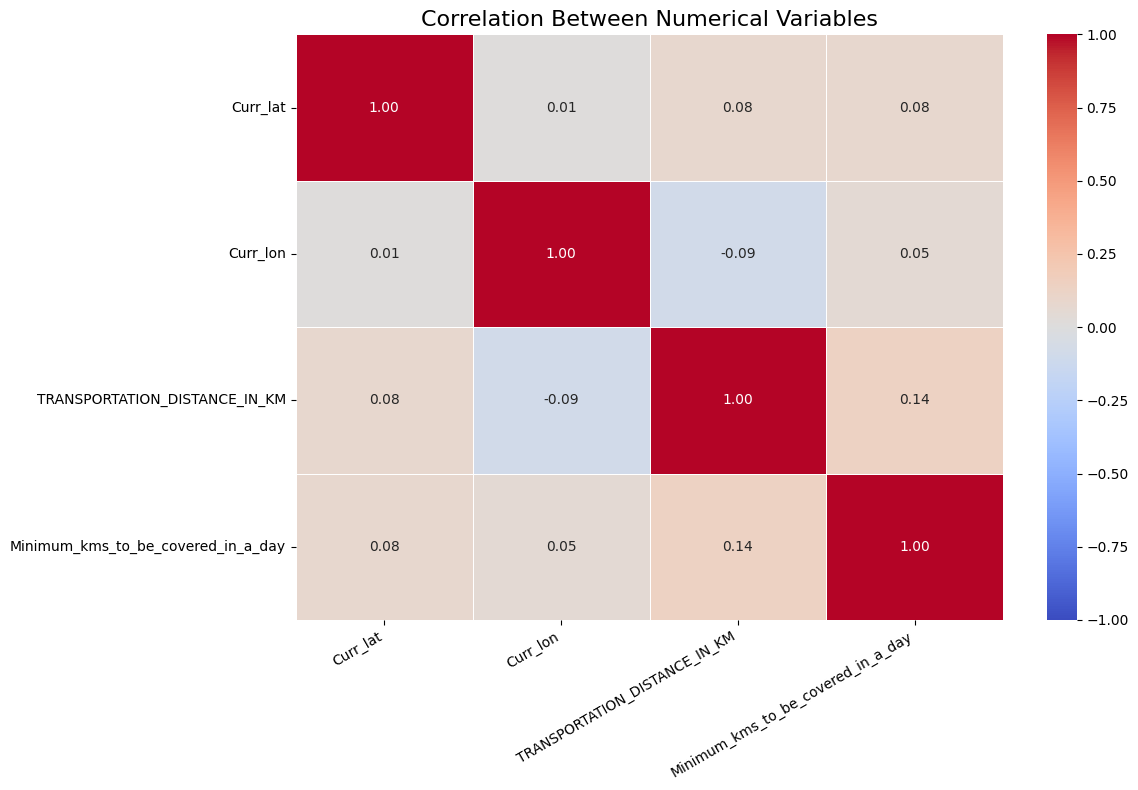

In [ ]:

numeric_cols = [
    "Curr_lat",
    "Curr_lon",
    "TRANSPORTATION_DISTANCE_IN_KM",
    "Minimum_kms_to_be_covered_in_a_day"
]

# Calculate correlation using TL
corr = TL[numeric_cols].corr()

# Create a larger heatmap
plt.figure(figsize=(12, 8))

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1,
    linewidths=0.5
)

plt.title("Correlation Between Numerical Variables", fontsize=16)
plt.xticks(rotation=30, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()